## ESTE PROYECTO BUSCAMOS PREDECIR FALLAS EN UN ESCENARIO DE MANUFACTURA SIMILAR AL PROCESO AUTROMOTRIZ DE HELLA

In [1]:
import pandas as pd
data=pd.read_csv("CSVS/ai4i2020.csv")

In [2]:
data

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [3]:
data.isna().mean()

UDI                        0.0
Product ID                 0.0
Type                       0.0
Air temperature [K]        0.0
Process temperature [K]    0.0
Rotational speed [rpm]     0.0
Torque [Nm]                0.0
Tool wear [min]            0.0
Machine failure            0.0
TWF                        0.0
HDF                        0.0
PWF                        0.0
OSF                        0.0
RNF                        0.0
dtype: float64

In [4]:
data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [5]:
data.dtypes 

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [6]:
numericas=["Air temperature [K]"	,"Process temperature [K]"	,"Rotational speed [rpm]"	,"Torque [Nm]"	,"Tool wear [min]"]
cats=["Type"]
fails=["TWF"	,"HDF"	,"PWF"	,"OSF"	,"RNF"]
target=["Machine failure"]

## AVERIGUAR QUE TAN DESBALANCEADO ESTA NUESTRO DATASET: ##

In [7]:
data["Machine failure"].value_counts()/10000 

Machine failure
0    0.9661
1    0.0339
Name: count, dtype: float64

COMO ESTA MUY DESBALANCEADO LO CONSIDERAREMOS A LA HORA DE HACER EL MODELO (ACURACY PARADOX: SI PREDECIMOS 0 PARA TODOS LOS DATOS ATINAREMOS EL 96.61%)

## VEEMOS LAS DISTRIBUCIONES DE CADA VARIABLE PARA BUSCAR OUTLIERS ##

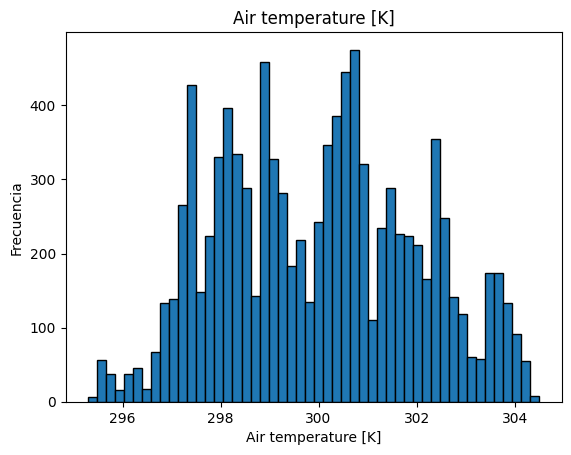

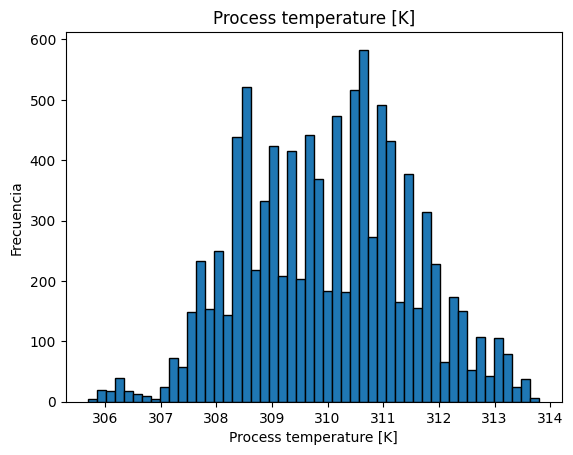

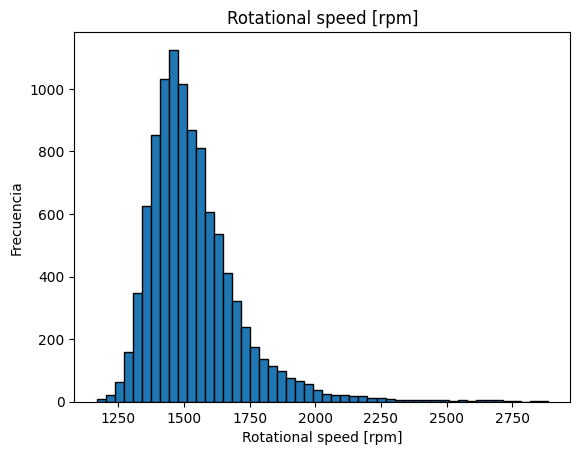

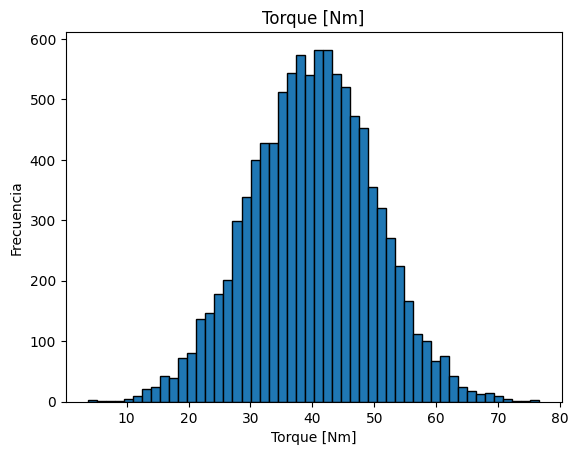

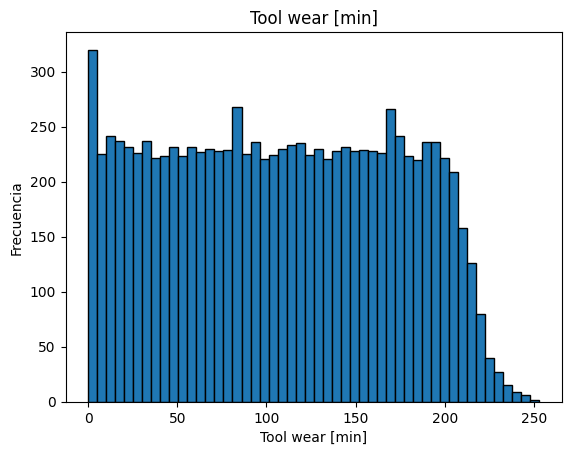

In [8]:
import matplotlib.pyplot as plt
for col in numericas: #enumerate se usa asi con dos variables, lo que hace es hacer una variable contadora (i) y col va iterando por las variables 
    plt.hist(data[col ], bins=50, edgecolor="black")
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()



Air temperature — es aproximadamente normal pero con ruido fuerte. Recuerda que en el dataset está generada con un random walk normalizado, eso explica la irregularidad.

Process temperature — aproximadamente normal con ligera cola derecha.

Rotational speed — distribución sesgada a la derecha con outliers. La masa está concentrada entre 1200-1600 rpm pero hay valores que llegan a 2886. Esos outliers de velocidad alta son candidatos a estar asociados con fallas.

Torque — es la más normal de todas, sí. Simétrica alrededor de ~40 Nm.

Tool wear —  distribución aproximadamente uniforme entre 0 y ~220 min, con un pico al inicio (muchas herramientas nuevas) y caída al final (las herramientas se reemplazan antes de llegar al límite máximo). Esto tiene sentido físico.

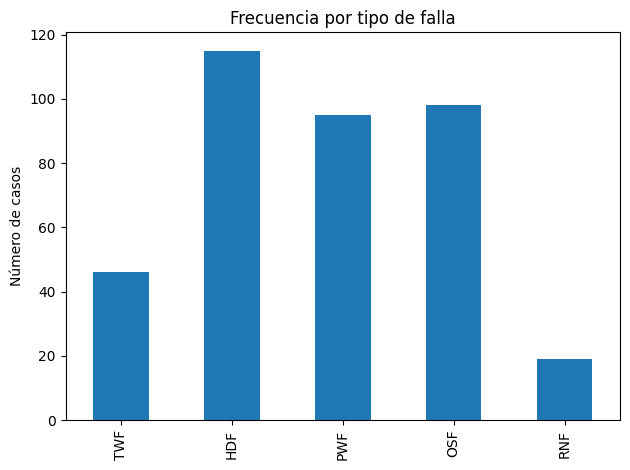

In [9]:

fails_counts = data[fails].sum()

plt.figure()
fails_counts.plot(kind='bar')
plt.title('Frecuencia por tipo de falla')
plt.ylabel('Número de casos')
plt.tight_layout()
plt.show()

La observación más importante que no mencionaste:
Rotational speed y Torque deberían estar correlacionados negativamente — a mayor velocidad, menor torque, porque Potencia = Torque × velocidad angular, y la potencia del proceso es aproximadamente constante.
Eso lo vamos a verificar ahora:

,Rotational speed [rpm],Torque [Nm]
Rotational speed [rpm],1.000000,-0.875027
Torque [Nm],-0.875027,1.000000


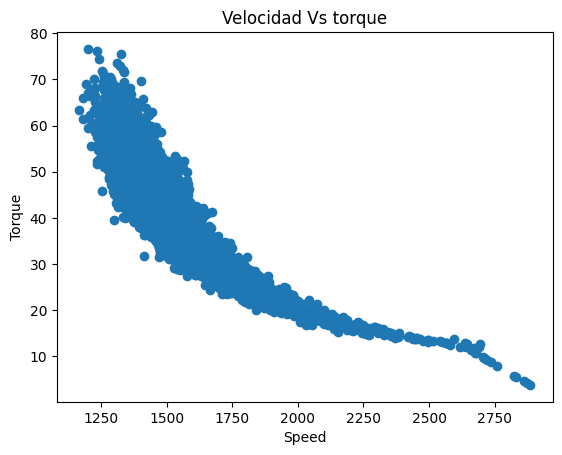

In [10]:
plt.figure()
plt.scatter(data["Rotational speed [rpm]"],  data['Torque [Nm]'])
plt.xlabel("Speed")
plt.ylabel("Torque")
plt.title("Velocidad Vs torque")

data[["Rotational speed [rpm]","Torque [Nm]"]].corr()

In [11]:
import numpy as np
data['Power'] = data['Torque [Nm]'] * (data['Rotational speed [rpm]'] * 2 * np.pi / 60)
data

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Power
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,6951.590560
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,6826.722724
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,7749.387543
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,5927.504659
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,5897.816608
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0,4955.129373
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0,5434.703963
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0,5753.617506
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0,7151.102638


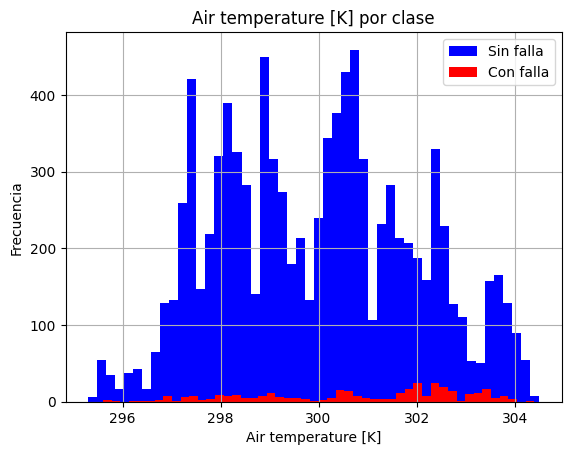

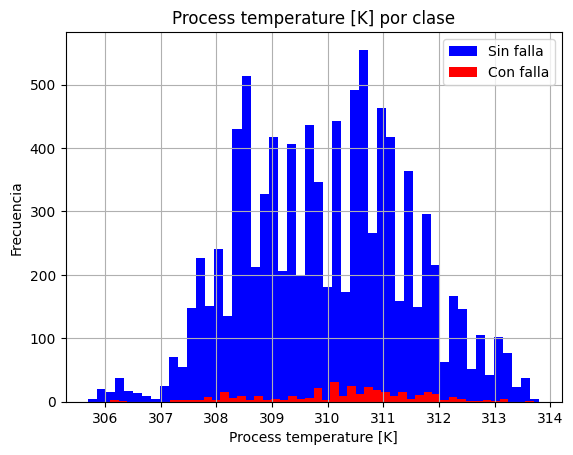

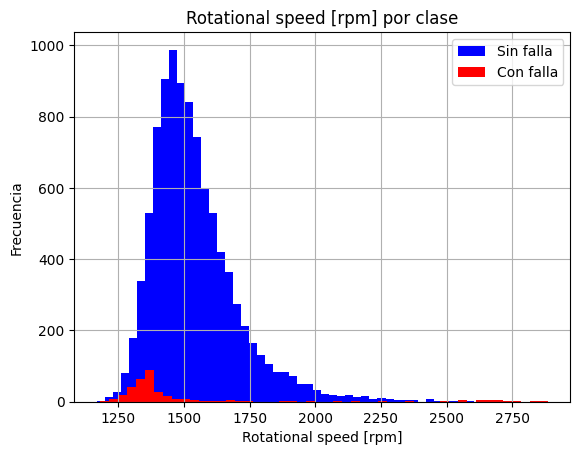

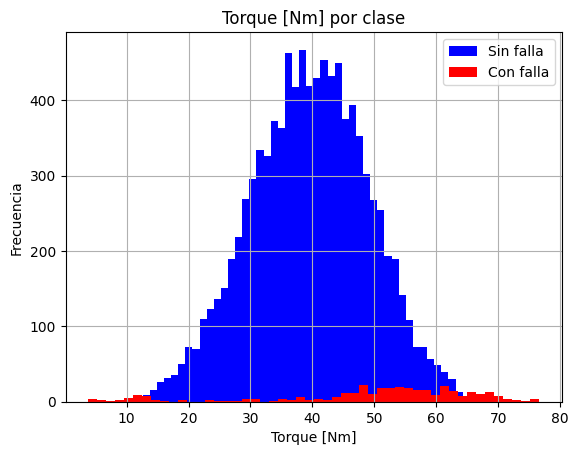

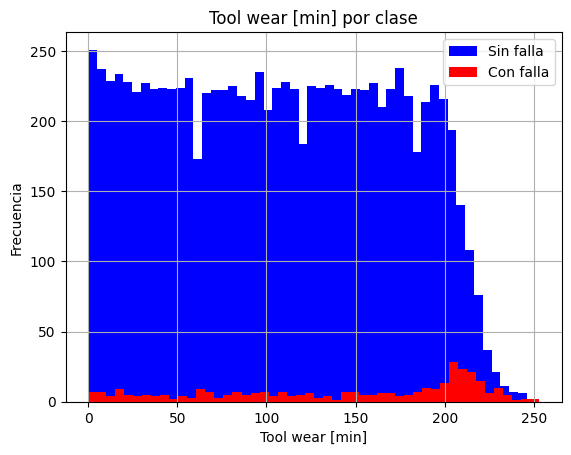

In [12]:
features = ['Air temperature [K]', 'Process temperature [K]', 
            'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

for col in features:
    plt.figure()
    data[data['Machine failure'] == 0][col].hist(bins=50, label='Sin falla', color='blue')
    data[data['Machine failure'] == 1][col].hist(bins=50,  label='Con falla', color='red')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.title(f'{col} por clase')
    plt.legend()
    plt.show()

Air temperature y Process temperature — las distribuciones roja y azul están completamente solapadas. Estas variables por sí solas no separan las clases. Bajo poder predictivo individual.
Torque — hay una señal débil. Las fallas parecen concentrarse ligeramente en los extremos (torque muy bajo <20 Nm y torque alto >55 Nm). Tiene sentido físico: torque anormalmente bajo o alto indica condición fuera de operación normal.
Tool wear — esta es la más importante de las cuatro. Las fallas (rojo) están claramente concentradas en valores altos de desgaste, especialmente después de 200 min. Tiene sentido físico directo: a mayor desgaste acumulado, mayor probabilidad de falla.

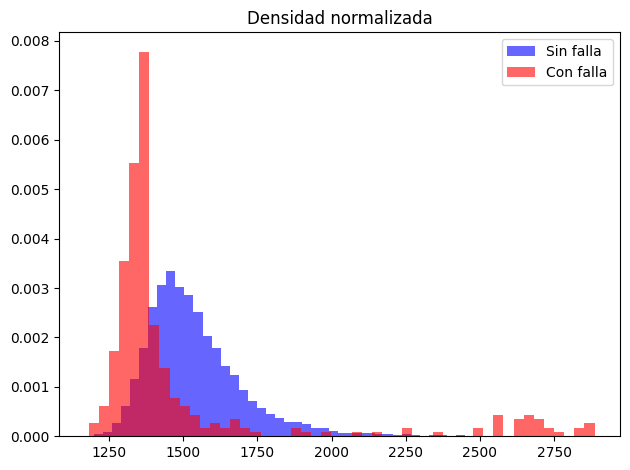

In [13]:
plt.figure()
plt.hist(data[data['Machine failure']==0]['Rotational speed [rpm]'], bins=50, alpha= 0.6, label='Sin falla', color='blue', density=True) #density=True le dices que en lugar de contar, divida cada barra entre
plt.hist(data[data['Machine failure']==1]['Rotational speed [rpm]'], bins=50,  alpha= 0.6, label='Con falla', color='red', density=True) #el total de observaciones de esa clase — convirtiendo los conteos a proporciones.
plt.title('Densidad normalizada')
plt.legend()
plt.tight_layout()
plt.show()

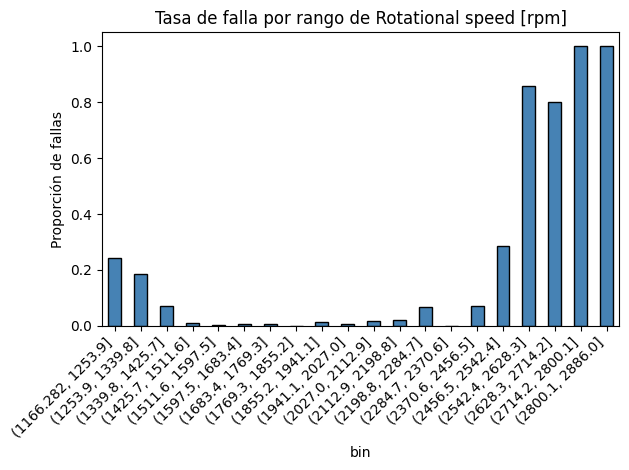

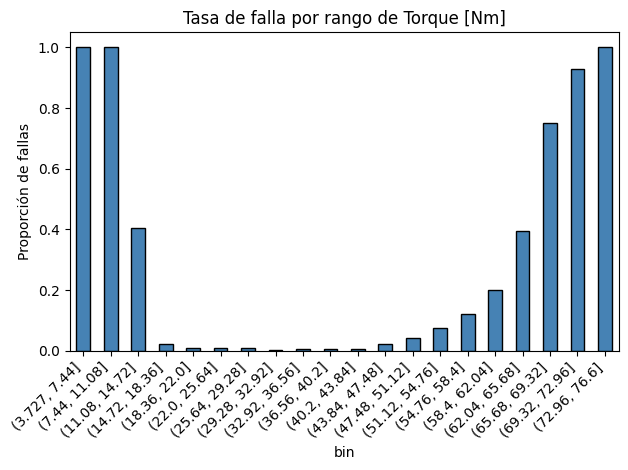

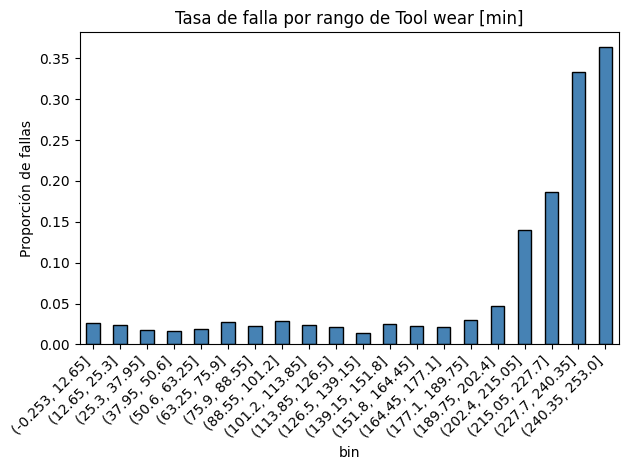

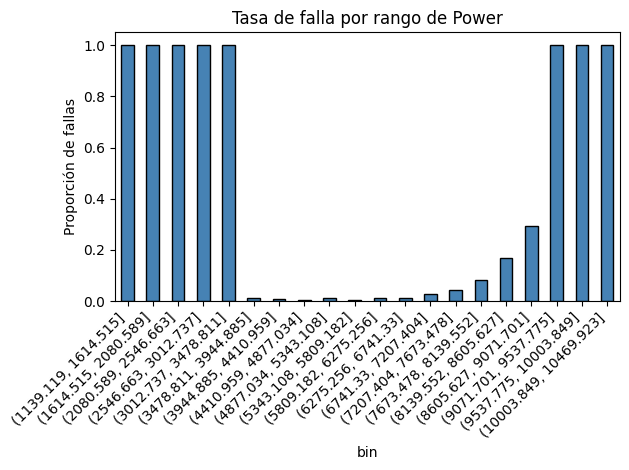

In [14]:
features = ['Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Power']

for col in features:
    data['bin'] = pd.cut(data[col], bins=20)
    #pd.cut divide el rango de valores de una variable continua en 20 intervalos iguales y 
    # le asigna a cada observación el intervalo al que pertenece. 
    # Por ejemplo, si RPM va de 1200 a 2900, crea 20 rangos de ~85 rpm cada uno y etiqueta cada fila con su rango correspondiente. 
    # El resultado se guarda como una nueva columna llamada bin.
    tasa = data.groupby('bin', observed=True)['Machine failure'].mean()
    #Agrupa todas las filas por su bin y calcula el promedio de Machine failure dentro de cada grupo. 
    #Como Machine failure es 0 o 1, el promedio es directamente la proporción de fallas en ese rango. 
    #observed=True es solo para evitar un warning de pandas — le dice que ignore categorías vacías.
    plt.figure()
    tasa.plot(kind='bar', color='steelblue', edgecolor='black')
    plt.title(f'Tasa de falla por rango de {col}')
    plt.ylabel('Proporción de fallas')
    plt.xticks(rotation=45, ha='right')
    #Rota las etiquetas del eje X 45 grados para que no se sobrepongan entre sí, ya que los intervalos tienen nombres largos como (1285, 1370]
    plt.tight_layout()
    plt.show()

data.drop(columns=['bin'], inplace=True)
#Elimina la columna bin que creamos temporalmente. No es una feature real — solo la usamos para el análisis.
#  inplace=True modifica el dataframe directamente sin necesidad de reasignarlo.

Se observa que la probabilidad de falla aumenta considerablemente en valores extremos de velocidad de rotación, torque y potencia. Sin embargo, los bins ubicados en las colas de la distribución contienen pocas observaciones, por lo que las tasas observadas en esas regiones deben interpretarse con cautela. Aun así, la tendencia general sugiere que condiciones operativas extremas están asociadas con una mayor probabilidad de falla.

## SPLIT DE DATOS

In [15]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder

# Eliminar columnas que no son features
data = data.drop(columns=['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'])

# Encodear Type
le = LabelEncoder()
data['Type'] = le.fit_transform(data['Type'])

# Features y target
X = data.drop(columns=['Machine failure'])
y = data['Machine failure']

# Train/test split — stratify mantiene la proporción 96.6/3.4 en ambos sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Cross validation estratificado — 5 folds
cvstrat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) #aqui tambien usamos una funcion para statificar los folds 

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"\nProporción target en train:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"\nProporción target en test:\n{y_test.value_counts(normalize=True).round(3)}")

Train: (8000, 7), Test: (2000, 7)

Proporción target en train:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64

Proporción target en test:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [16]:
# Limpiar nombres de columnas porque ya habia corrido el codigo de abajo pero trono por los nombres
X_train.columns = X_train.columns.str.replace('[', '', regex=False).str.replace(']', '', regex=False)
X_test.columns = X_test.columns.str.replace('[', '', regex=False).str.replace(']', '', regex=False)

print(X_train.columns.tolist())

['Type', 'Air temperature K', 'Process temperature K', 'Rotational speed rpm', 'Torque Nm', 'Tool wear min', 'Power']


## MODELADO Y MATRIZ DE CONFUSION

In [ ]:
import xgboost as xgb
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

# Ratio para manejar desbalance — le dice a XGBoost que pese más las fallas porque:
#En manufactura automotriz el False Negative es mucho más costoso que el False Positive. 
#scale_pos_weight para que el modelo sea agresivo detectando fallas — prefiere generar falsas alarmas antes que perderse una falla real. 
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.1f}")


# Modelo
modelo = xgb.XGBClassifier(
    n_estimators=1000,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    tree_method='hist'
    eval_metric='aucpr',
    random_state=42,
    early_stopping_rounds=100,
    n_jobs=-1
)

# Cross validation sobre train — métrica: PR-AUC
scores = cross_val_score(modelo, X_train, y_train, cv=cvstrat, scoring='average_precision')
print(f"\nPR-AUC por fold: {scores.round(3)}")
print(f"PR-AUC promedio: {scores.mean():.3f} (+/- {scores.std():.3f})")

# Entrenamiento final sobre todo el train
modelo.fit(X_train, y_train)

# Evaluación sobre test
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print(f"\nROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_prob):.3f}")
print(f"\n{classification_report(y_test, y_pred)}")

scale_pos_weight: 28.5

PR-AUC por fold: [0.858 0.751 0.788 0.81  0.822]
PR-AUC promedio: 0.806 (+/- 0.036)

ROC-AUC: 0.971
PR-AUC:  0.805

              precision    recall  f1-score   support

           0       0.99      0.97      0.98      1932
           1       0.54      0.85      0.66        68

    accuracy                           0.97      2000
   macro avg       0.77      0.91      0.82      2000
weighted avg       0.98      0.97      0.97      2000



Support — cuántas observaciones reales hay de cada clase en el test set. 1932 sin falla, 68 con falla.

Precision — de todo lo que el modelo predijo como falla, ¿qué % realmente era falla? 54% — de cada 100 alarmas que dispara, 54 son reales y 46 son falsas alarmas.

Recall — de todas las fallas reales, ¿qué % detectó el modelo? 85% — detecta 58 de las 68 fallas reales.

F1 — promedio armónico entre precision y recall. Útil como métrica única pero no suficiente sola.

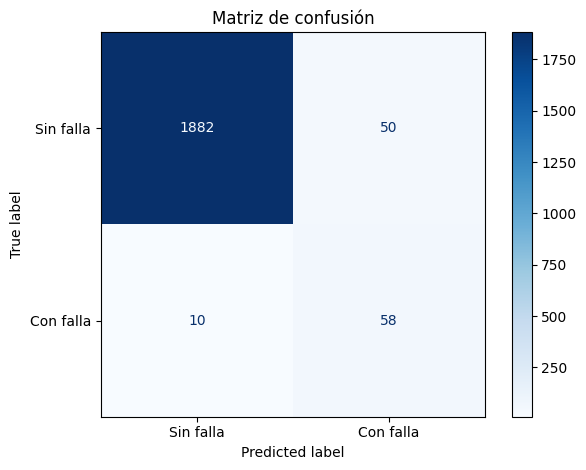

Verdaderos Negativos (TN): 1882 — sin falla, predijo sin falla
Falsos Positivos  (FP): 50 — sin falla, predijo falla
Falsos Negativos  (FN): 10 — con falla, predijo sin falla
Verdaderos Positivos (TP): 58 — con falla, predijo falla


In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sin falla', 'Con falla'])

disp.plot(cmap='Blues')
plt.title('Matriz de confusión')
plt.tight_layout()
plt.show()

# Desglose manual para claridad
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos Negativos (TN): {tn} — sin falla, predijo sin falla")
print(f"Falsos Positivos  (FP): {fp} — sin falla, predijo falla")
print(f"Falsos Negativos  (FN): {fn} — con falla, predijo sin falla")
print(f"Verdaderos Positivos (TP): {tp} — con falla, predijo falla")

¿Vale la pena generar 50 falsas alarmas para atrapar 58 de 68 fallas reales? probablemente sí — pero eso lo decide el negocio, no el modelo.
Si quisieras atrapar las 10 fallas restantes tendrías que bajar el threshold de decisión, lo que generaría aún más falsas alarmas. Ese es el tradeoff fundamental de precision vs recall.

In [24]:
# Ver las probabilidades de los 10 FN
false_negatives_idx = (y_pred == 0) & (y_test.values == 1)
probs_fn = y_prob[false_negatives_idx]
print("Probabilidades de falla en los 10 FN:")
print(sorted(probs_fn.round(3)))

Probabilidades de falla en los 10 FN:
[np.float32(0.003), np.float32(0.007), np.float32(0.01), np.float32(0.049), np.float32(0.073), np.float32(0.085), np.float32(0.122), np.float32(0.294), np.float32(0.322), np.float32(0.333)]


In [25]:
threshold = 0.27
y_pred_nuevo = (y_prob >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_nuevo).ravel()
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")
print(f"\nRecall:    {tp/(tp+fn):.3f}")
print(f"Precision: {tp/(tp+fp):.3f}")

TN: 1830, FP: 102, FN: 7, TP: 61

Recall:    0.897
Precision: 0.374


## SHAP VALUES: ENTENDIMIENTO DE COMO CLASIFICA EL MODELO

C:\Users\carla\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


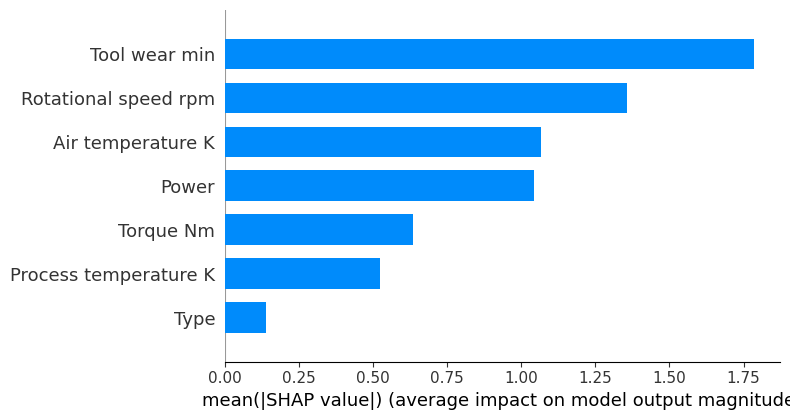

In [20]:
import shap

explainer = shap.TreeExplainer(modelo)
shap_values = explainer.shap_values(X_test)

# Importancia global de features
shap.summary_plot(shap_values, X_test, plot_type='bar')

GRAFICO DE IMPORTANCIA GLOBAL: qué tanto mueve cada variable las predicciones en promedio, sin importar en qué dirección.

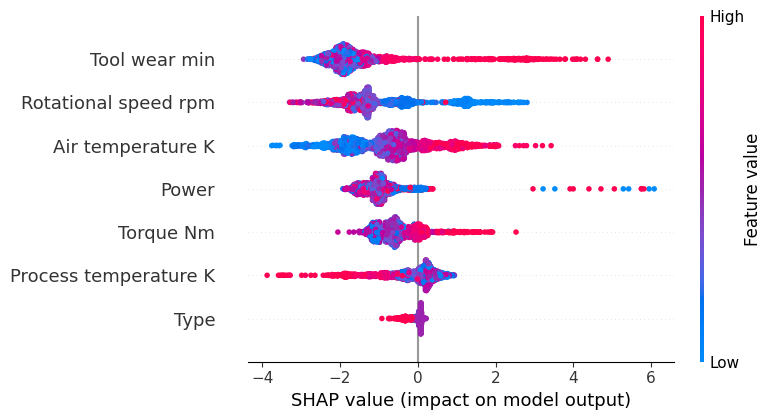

In [21]:
shap.summary_plot(shap_values, X_test)

Lo más informativo es ver un True Positive — un caso que es falla real Y el modelo detectó correctamente. Ahí el SHAP te muestra qué señales físicas reales llevaron a la detección correcta:

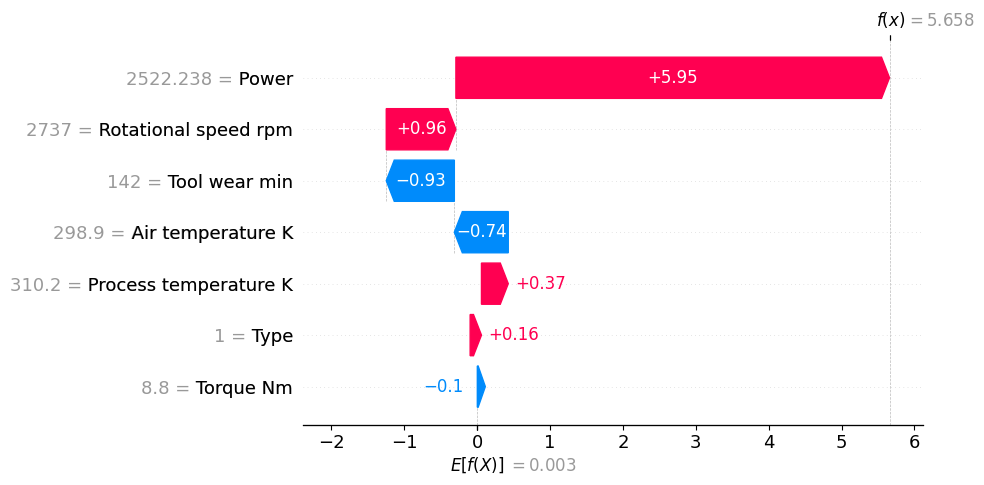

In [22]:
# Índices donde es falla real Y el modelo predijo falla correctamente
true_positives = (y_pred == 1) & (y_test.values == 1)
primer_tp = true_positives.argmax()

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[primer_tp],
        base_values=explainer.expected_value,
        data=X_test.iloc[primer_tp],
        feature_names=X_test.columns.tolist()
    )
)

E[f(x)] = 0.003. Si el modelo no supiera nada de este proceso, predicción de falla sería 0.3% (la tasa base del dataset).
f(x) = 5.658 el score final del modelo para esta observación. Un valor muy alto, el modelo está muy seguro de que es falla.
La máquina estaba girando a 2737 rpm (muy alta) con solo 8.8 Nm de torque (muy bajo) — lo que da una potencia anormalmente baja. Esa combinación extrema de alta velocidad + torque mínimo es lo que el modelo detectó como condición de falla, no el desgaste de la herramienta.

Valores del proceso:
Type                        1.000000
Air temperature K         303.700000
Process temperature K     312.100000
Rotational speed rpm     1363.000000
Torque Nm                  51.800000
Tool wear min              90.000000
Power                    7393.570759
Name: 4851, dtype: float64

Predicción del modelo: 0
Realidad: 1


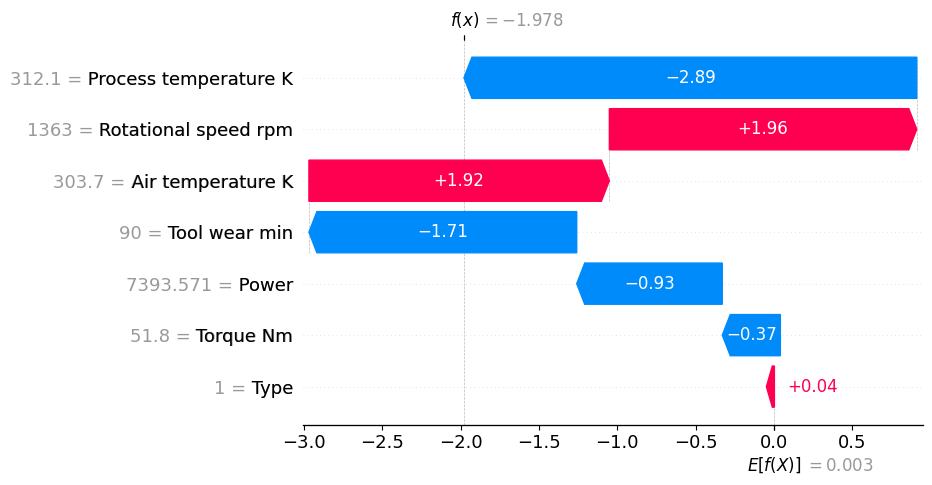

In [23]:
# Índices donde es falla real pero el modelo predijo normal (False Negative)
false_negatives = (y_pred == 0) & (y_test.values == 1)
primer_fn = false_negatives.argmax()

print(f"Valores del proceso:\n{X_test.iloc[primer_fn]}")
print(f"\nPredicción del modelo: {y_pred[primer_fn]}")
print(f"Realidad: {y_test.values[primer_fn]}")

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[primer_fn],
        base_values=explainer.expected_value,
        data=X_test.iloc[primer_fn],
        feature_names=X_test.columns.tolist()
    )
)

## CONCLUSIONES:
DEMASIADO EDA:
LO UNICO QUE ERA NECESARIO DE LAS GRAFICAS FUE LA ULTIMA DONDE VIMOS LOS CUTS Y SU PROPORCION DE FALLOS.
ES MAS QUE SUFICIENTES CON VER SI PUEDES CREAR UNAS VARIABLES NUEVAS A PARTIR DE ENTENDER MUY BIEN LAS VARIBALES Y DATOS QUE TIENES Y LO QUE QUIERES CONSEGUIR CON TU ANALISIS 
NO USE EL EVAL SET:
MUY UTIL CON XGBOOST PORQUE OPTIMIZAS EL NUMERO DE ARBOLES PARA EVITAR OVERFITING, COMBINADO CON EARLY STOPPING AUNQUE SIGA MEJORANDO EN TRAIN SI EL EVAL EMPIEZA A EMPEORAR AHI DETIENE.